# MakeMore

## Model Bigram

The idea of this model is to try to predict the next letter given the current one. In order to do it, it will use a Multinomial Distribution such that it sorts the next character given the probability distribution of it.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch

In [32]:
words = open('names.txt', 'r').read().splitlines()

In [3]:
chars = sorted(set(''.join(words)))
stoi = {i:s+1 for s, i in enumerate(chars)}
stoi["."] = 0
itos = {i:s for s,i in stoi.items()}

In [4]:
#We are going to store the information about the frequency of pairs of letters in a Torch.tensor object. Note that it's 27x27 because we are using 
#the character "." to specify that it is either the start or the end of a word.
N = torch.zeros((27,27), dtype = torch.int32)

for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        N[stoi[ch1],stoi[ch2]] += 1

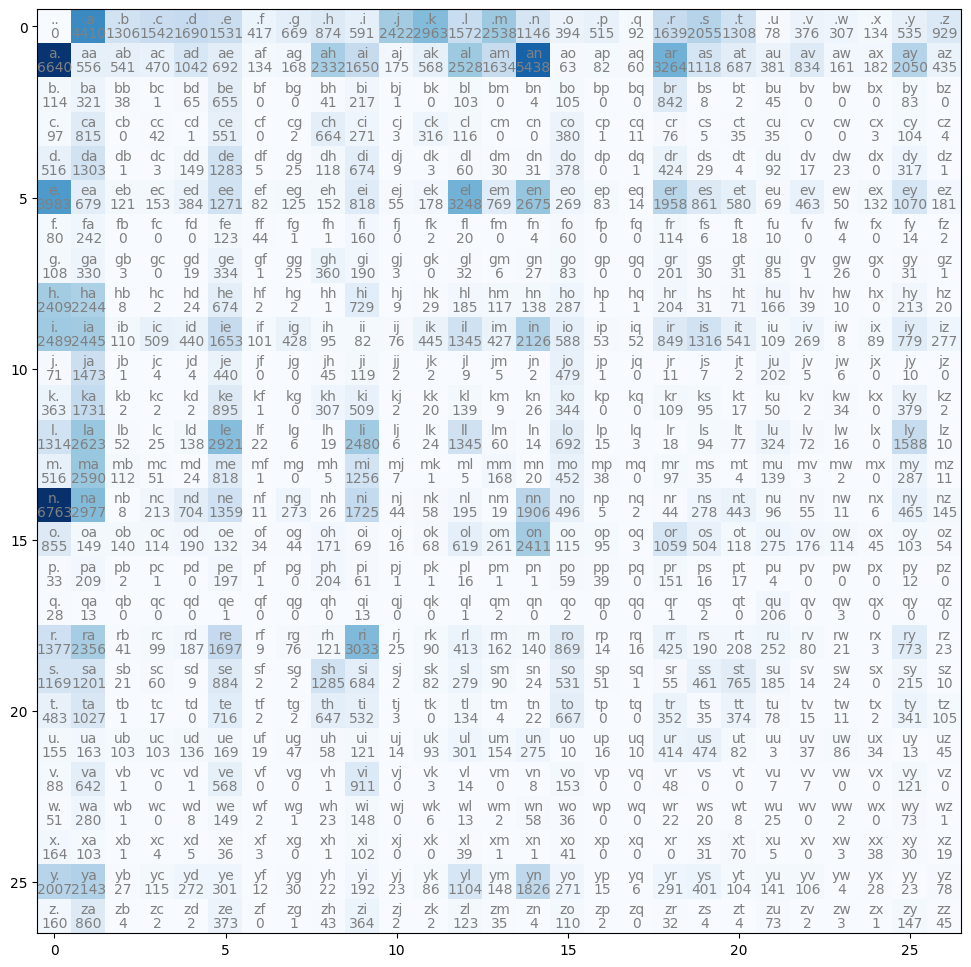

In [ ]:
#Here we see the distribution of the pairs.
plt.figure(figsize = (12,12))
plt.imshow(N, cmap = "Blues")
for i in range(27):
    for j in range(27):
        chstr = itos[i]+itos[j]
        plt.text(j, i, chstr, ha = "center", va = "bottom", color = "gray")
        plt.text(j, i, N[i, j].item(), ha ="center", va = "top", color = "gray" )
plt.show()

In [6]:
#We convert N to a probability distribution at each row.
P = N.float() +1
P = P/P.sum(dim = 1, keepdim = True)
P[0]

tensor([3.1192e-05, 1.3759e-01, 4.0767e-02, 4.8129e-02, 5.2745e-02, 4.7785e-02,
        1.3038e-02, 2.0898e-02, 2.7293e-02, 1.8465e-02, 7.5577e-02, 9.2452e-02,
        4.9064e-02, 7.9195e-02, 3.5777e-02, 1.2321e-02, 1.6095e-02, 2.9008e-03,
        5.1154e-02, 6.4130e-02, 4.0830e-02, 2.4641e-03, 1.1759e-02, 9.6070e-03,
        4.2109e-03, 1.6719e-02, 2.9008e-02])

In [34]:
gen = torch.Generator().manual_seed(2147483647)
N_it = 5
for i in range(N_it):
    out = []
    ix = 0 
    while True:
        p = P[ix]
        ix = torch.multinomial(p, num_samples = 1, replacement = True, generator = gen).item()
        out.append(itos[ix])
        if ix == 0:
            break
    print("".join(out))
            


junide.
janasah.
p.
cony.
a.


## Neural Network Approach

So far, we have trained a model whose parameters are stored in a matrix P of size 27x27. This matrix represents the transition probabilities between characters, where each entry P[i, j] gives the probability of transitioning from character i to character j. Words are generated by sampling from a multinomial distribution based on these probabilities.

However, the model is not performing well enough. One major limitation is the lack of a quantitative measure to evaluate the quality of the generated words. Specifically, we need a way to assess how "reasonable" the generated words are by measuring their likelihood under the model.

### Negative Log Likelihood

In [8]:
gen = torch.Generator().manual_seed(2147483647)
N_it = 5
for i in range(N_it):
    out = []
    ix = 0 
    while True:
        p = P[ix]
        ix = torch.multinomial(p, num_samples = 1, replacement = True, generator = gen).item()
        out.append(itos[ix])
        if ix == 0:
            break
    print("".join(out))

junide.
janasah.
p.
cony.
a.


In [9]:
logprob = 0
count = 0
for w in words[:3]:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        prob = P[ix1,ix2]
        logprob += torch.log(prob)
        count += 1
        print(f"{ch1, ch2}, prob = {prob:.4f}, logprob = {logprob:.4f}")
print(f"-LogLikeLihood = {logprob/count}")

('.', 'e'), prob = 0.0478, logprob = -3.0410
('e', 'm'), prob = 0.0377, logprob = -6.3204
('m', 'm'), prob = 0.0253, logprob = -9.9957
('m', 'a'), prob = 0.3885, logprob = -10.9411
('a', '.'), prob = 0.1958, logprob = -12.5716
('.', 'o'), prob = 0.0123, logprob = -16.9681
('o', 'l'), prob = 0.0779, logprob = -19.5207
('l', 'i'), prob = 0.1774, logprob = -21.2500
('i', 'v'), prob = 0.0152, logprob = -25.4345
('v', 'i'), prob = 0.3508, logprob = -26.4821
('i', 'a'), prob = 0.1380, logprob = -28.4628
('a', '.'), prob = 0.1958, logprob = -30.0933
('.', 'a'), prob = 0.1376, logprob = -32.0768
('a', 'v'), prob = 0.0246, logprob = -35.7809
('v', 'a'), prob = 0.2473, logprob = -37.1781
('a', '.'), prob = 0.1958, logprob = -38.8086
-LogLikeLihood = -2.4255354404449463


Input and Target Sequences:

xs: Input tensor representing the current characters (e.g., [0, 5, 13, 13, 1]).

ys: Target tensor representing the next characters (e.g., [5, 13, 13, 1, 0]).

Weight Initialization:

We randomly initialize a weight matrix W of size (27, 27) using a fixed seed for reproducibility. Each of the 27 neurons receives 27 inputs, corresponding to the 27 possible characters (26 letters + a special token).

One-Hot Encoding:

The input sequence xs is converted into a one-hot encoded matrix xenc, where each character is represented as a 27-dimensional binary vector.

Logits and Probabilities:

The one-hot encoded input is multiplied by the weight matrix W to produce logits, which represent unnormalized log-counts.

The logits are exponentiated to obtain counts, which are then normalized using a softmax function to produce probabilities for the next character.

This process forms the foundation of our model, which aims to predict the next character in a sequence based on the current character. The next steps would involve training the model to optimize the weights W using a loss function and evaluating its performance.

In [110]:
# Create the training set of bigrams

xs, ys = [], []

for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        xs.append(ix1), ys.append(ix2)

xs = torch.tensor(xs)
ys = torch.tensor(ys)
num = xs.nelement()

In [111]:
import torch.nn.functional as F

Xenc = F.one_hot(xs, num_classes = 27).float()
Yenc = F.one_hot(ys, num_classes = 27).float()

Xenc.shape

torch.Size([228146, 27])

In [112]:
g = torch.Generator().manual_seed(123)
W = torch.randn((27,27), requires_grad = True)


In [139]:
logits = Xenc @ W #Log of Counts
counts = logits.exp() # Equivalent tp N
probs = counts/counts.sum(1, keepdims = True)
loss = - probs[torch.arange(num),ys].log().mean()


W.grad = None
loss.backward()

In [140]:
print(loss.item())

2.9669766426086426


In [141]:
W.data += - 50*W.grad

In [ ]:
g = torch.Generator().manual_seed(123)
W = torch.randn((27,27), requires_grad = True)

Xenc = F.one_hot(xs, num_classes = 27).float()
Yenc = F.one_hot(ys, num_classes = 27).float()

Xenc.shape
for k in range(200):
    logits = Xenc @ W #Log of Counts
    counts = logits.exp() # Equivalent tp N
    probs = counts/counts.sum(1, keepdims = True)
    loss = - probs[torch.arange(num),ys].log().mean() + 0.01*(W**2).mean()


    W.grad = None
    loss.backward()
    W.data += - 50*W.grad
    if k%10 == 0:
        print(f"epoch = {k}, loss = {loss}")

epoch = 0, loss = 3.8382647037506104
epoch = 10, loss = 2.6801047325134277
epoch = 20, loss = 2.582303285598755
epoch = 30, loss = 2.544888734817505
epoch = 40, loss = 2.5248260498046875
epoch = 50, loss = 2.512796401977539
epoch = 60, loss = 2.505042552947998
epoch = 70, loss = 2.4997518062591553
epoch = 80, loss = 2.4959869384765625
epoch = 90, loss = 2.4932117462158203
epoch = 100, loss = 2.4911038875579834
epoch = 110, loss = 2.489464282989502
epoch = 120, loss = 2.4881629943847656
epoch = 130, loss = 2.487114667892456
epoch = 140, loss = 2.4862582683563232
epoch = 150, loss = 2.4855499267578125
epoch = 160, loss = 2.484957218170166
epoch = 170, loss = 2.4844565391540527
epoch = 180, loss = 2.4840292930603027
epoch = 190, loss = 2.4836618900299072


In [149]:
probs

tensor([[1.8949e-04, 1.3766e-01, 4.0763e-02,  ..., 4.1756e-03, 1.6694e-02,
         2.8994e-02],
        [1.9502e-01, 3.3244e-02, 5.9218e-03,  ..., 6.4605e-03, 5.2389e-02,
         8.8598e-03],
        [7.7452e-02, 3.8971e-01, 1.6611e-02,  ..., 5.4205e-04, 4.2971e-02,
         1.5653e-03],
        ...,
        [2.0527e-01, 2.1918e-01, 2.7203e-03,  ..., 2.7488e-03, 2.3131e-03,
         7.9385e-03],
        [6.5784e-02, 3.5773e-01, 2.0310e-03,  ..., 1.0835e-03, 6.0359e-02,
         1.7583e-02],
        [2.3161e-01, 1.4399e-01, 5.3533e-03,  ..., 4.8337e-02, 3.7750e-02,
         2.3386e-02]], grad_fn=<DivBackward0>)

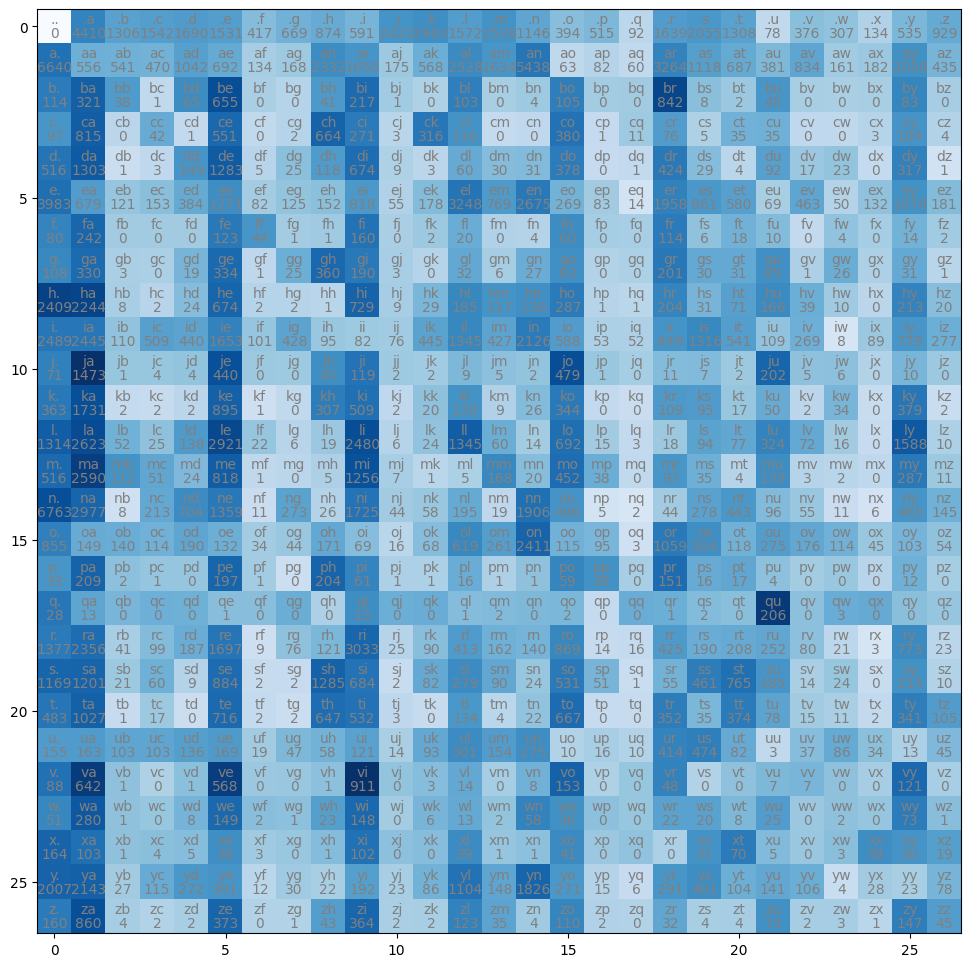

In [153]:
plt.figure(figsize = (12,12))
plt.imshow(W.detach().numpy(), cmap = "Blues")
for i in range(27):
    for j in range(27):
        chstr = itos[i]+itos[j]
        plt.text(j, i, chstr, ha = "center", va = "bottom", color = "gray")
        plt.text(j, i, N[i, j].item(), ha ="center", va = "top", color = "gray" )
plt.show()